# 3. Solutions, Evaluation and Discussion


In [1]:
# Shared Sudoku helpers (needed by Methods 2 and 3)
import random, math, time
import numpy as np

# Sudoku as a CSP: 81 cells, values 1-9, no repeats in any row, column or box
ROWS  = [[r * 9 + c for c in range(9)] for r in range(9)]
COLS  = [[r * 9 + c for r in range(9)] for c in range(9)]
BOXES = [[(br * 3 + r) * 9 + bc * 3 + c for r in range(3) for c in range(3)]
         for br in range(3) for bc in range(3)]
UNITS = ROWS + COLS + BOXES                                                         # 27 units
PEERS = [sorted({p for u in UNITS if i in u for p in u} - {i}) for i in range(81)]  # 20 peers each

def parse(puzzle):            # "530070..." -> [5, 3, 0, 0, 7, ...]
    return [int(ch) for ch in puzzle.strip().replace(".", "0")]

def to_string(grid):          # [5, 3, 4, ...] -> "534..."
    return "".join(map(str, grid))

def is_valid_solution(puzzle, solution):
    """True if the solution keeps the clues and every row, column and box has 1-9 once."""
    if solution is None: return False
    p, s = parse(puzzle), parse(solution)
    if any(a and a != b for a, b in zip(p, s)): return False
    return all(sorted(s[i] for i in u) == list(range(1, 10)) for u in UNITS)

def clues_consistent(puzzle):
    """False if the given clues already break a rule """
    g = parse(puzzle)
    for u in UNITS:
        vals = [g[i] for i in u if g[i]]
        if len(vals) != len(set(vals)): return False
    return True

## 3.2 Image Recognition

### Step 0: Setup and Imports

In [2]:
!pip -q install opencv-python-headless
import cv2                     # OpenCV: image processing (threshold, contours, warp)
import numpy as np             # arrays / maths
import random, glob, os
from PIL import Image, ImageDraw, ImageFont   # used to draw synthetic Sudoku images and digits
import matplotlib



#  Liberation fonts are added if the system has them.
_mpl_fonts = os.path.join(os.path.dirname(matplotlib.__file__), "mpl-data", "fonts", "ttf")
FONT_FILES = sorted(glob.glob(os.path.join(_mpl_fonts, "DejaVu*.ttf")) +
                    glob.glob("/usr/share/fonts/truetype/liberation*/*.ttf"))
FONT_FILES = [f for f in FONT_FILES if "Display" not in f]

import matplotlib.pyplot as plt
print("fonts found:", len(FONT_FILES))

fonts found: 24


### Step 1: Create Test Images

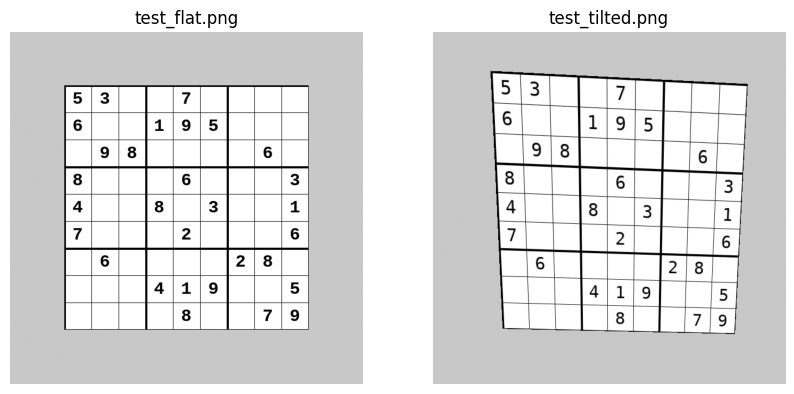

In [3]:

def make_synthetic_sudoku(puzzle, path, size=450, tilt=True, seed=0):
    """Draw a Sudoku (81-char string, '0' = empty) as an image and save it."""
    rnd = random.Random(seed)
    img = Image.new("L", (size, size), 255)          # white greyscale canvas
    d = ImageDraw.Draw(img)
    c = size / 9                                     # width of one cell in pixels
    for i in range(10):                              # 10 lines each way make 9 cells
        w = 4 if i % 3 == 0 else 1                   # thick lines around 3x3 boxes
        d.line([(i * c, 0), (i * c, size)], fill=0, width=w)   # vertical line
        d.line([(0, i * c), (size, i * c)], fill=0, width=w)   # horizontal line
    font = ImageFont.truetype(rnd.choice(FONT_FILES), int(c * 0.65))
    for k, ch in enumerate(puzzle):
        if ch != "0":
            r, col = divmod(k, 9)                    # index 0..80 -> (row, column)
            d.text(((col + 0.5) * c, (r + 0.5) * c), ch, fill=0, font=font, anchor="mm")  # centred
    grid = np.array(img)
    canvas = np.full((size + 200, size + 200), 200, np.uint8)   # grey "table" around the puzzle
    if tilt:
        # move each corner by a random amount -> perspective distortion
        src = np.float32([[0, 0], [size, 0], [size, size], [0, size]])
        j = lambda: rnd.uniform(-35, 35)
        dst = np.float32([[100 + j(), 100 + j()], [100 + size + j(), 100 + j()],
                          [100 + size + j(), 100 + size + j()], [100 + j(), 100 + size + j()]])
        M = cv2.getPerspectiveTransform(src, dst)
        warped = cv2.warpPerspective(grid, M, canvas.shape[::-1], borderValue=0)
        mask = cv2.warpPerspective(np.full_like(grid, 255), M, canvas.shape[::-1])
        canvas[mask > 0] = warped[mask > 0]          # paste the tilted puzzle onto the background
    else:
        canvas[100:100 + size, 100:100 + size] = grid
    cv2.imwrite(path, canvas)
    return path

TEST_PUZZLE = "530070000600195000098000060800060003400803001700020006060000280000419005000080079"
make_synthetic_sudoku(TEST_PUZZLE, "test_flat.png", tilt=False)
make_synthetic_sudoku(TEST_PUZZLE, "test_tilted.png", tilt=True, seed=3)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, f in zip(ax, ["test_flat.png", "test_tilted.png"]):
    a.imshow(cv2.imread(f, 0), cmap="gray"); a.set_title(f); a.axis("off")
plt.show()

### Step 2: Image Pre-processing

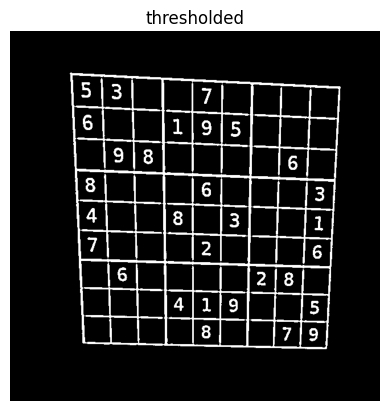

In [4]:

def preprocess(gray):
    """Greyscale image -> black/white image where lines and digits are WHITE."""
    blur = cv2.GaussianBlur(gray, (7, 7), 0)
    # Adaptive threshold: each pixel is compared with its local neighbourhood (11x11),
    # so it still works when one side of the photo is darker than the other.
    # THRESH_BINARY_INV makes dark ink -> white (255), paper -> black (0).
    return cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, 11, 2)

def order_corners(pts):
    """Sort 4 corner points into: top-left, top-right, bottom-right, bottom-left."""
    pts = np.array(pts, dtype="float32").reshape(4, 2)
    s = pts.sum(axis=1)                      # x + y: smallest = top-left, largest = bottom-right
    diff = np.diff(pts, axis=1).ravel()      # y - x: smallest = top-right, largest = bottom-left
    return np.float32([pts[np.argmin(s)], pts[np.argmin(diff)], pts[np.argmax(s)], pts[np.argmax(diff)]])

gray = cv2.imread("test_tilted.png", 0)
thresh = preprocess(gray)
plt.imshow(thresh, cmap="gray"); plt.title("thresholded"); plt.axis("off"); plt.show()

### Step 3: Grid Detection

In [5]:

def find_grid_corners(thresh):
    """Return the 4 corners of the Sudoku grid (largest 4-sided contour), or None if not found."""
    # 1. find the outlines of all white shapes in the black/white image
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # 2. check the shapes from biggest to smallest
    for cnt in sorted(contours, key=cv2.contourArea, reverse=True):
        # 3. simplify the outline so it only keeps its main corners
        peri = cv2.arcLength(cnt, True)
        approx = cv2.approxPolyDP(cnt, 0.02 * peri, True)
        # 4. a shape with 4 corners = the Sudoku grid
        if len(approx) == 4:
            return order_corners(approx)
    # 5. no 4-cornered shape found
    return None

### Step 4: Perspective Transform

[[106.  73.]
 [580.  98.]
 [555. 558.]
 [127. 547.]]


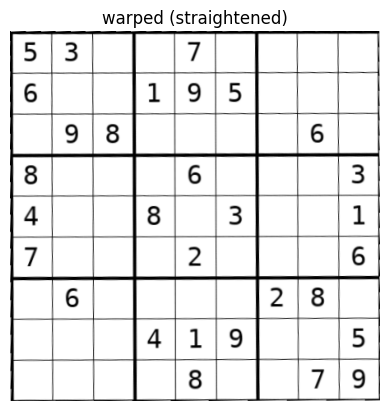

In [6]:

def warp_grid(gray, corners, size=450):
    """Straighten the grid: map the 4 tilted corners onto a flat size x size square."""
    dst = np.float32([[0, 0], [size - 1, 0], [size - 1, size - 1], [0, size - 1]])  # flat square corners
    M = cv2.getPerspectiveTransform(corners, dst)        # transformation tilted -> flat
    return cv2.warpPerspective(gray, M, (size, size))    # apply it to the whole image

# Test
corners = find_grid_corners(thresh); print(corners)
warped = warp_grid(gray, corners)
plt.imshow(warped, cmap="gray"); plt.title("warped (straightened)"); plt.axis("off"); plt.show()

### Step 5: Cell Extraction and Empty-Cell Detection

empty cells: 51 / 81


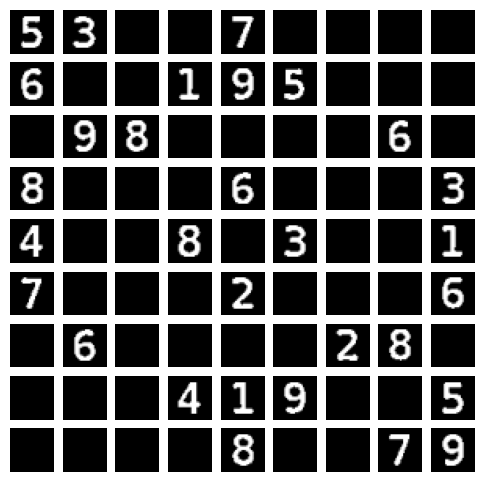

In [7]:

def cell_to_input(cell_bin):
    h, w = cell_bin.shape
    m = int(0.12 * h)
    inner = cell_bin[m:h - m, m:w - m]                  # to remove the grid lines

    n, labels, stats, _ = cv2.connectedComponentsWithStats(inner, 8)
    if n <= 1:                                          # only background -> empty cell
        return None
    i = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])      # biggest blob = the digit
    if stats[i, cv2.CC_STAT_AREA] < 0.03 * inner.size:  # tiny blob = noise -> empty cell
        return None
    x, y, bw, bh = stats[i, :4]                         # bounding box of the digit
    digit = (labels[y:y + bh, x:x + bw] == i).astype(np.uint8) * 255
    s = max(bw, bh)                                     # put it in a square (keeps its shape)
    sq = np.zeros((s, s), np.uint8)
    sq[(s - bh) // 2:(s - bh) // 2 + bh, (s - bw) // 2:(s - bw) // 2 + bw] = digit
    sq = cv2.resize(sq, (20, 20), interpolation=cv2.INTER_AREA)   # shrink digit to 20x20
    out = np.zeros((28, 28), np.float32)
    out[4:24, 4:24] = sq / 255.0                        # 4-pixel border, values 0..1
    return out

def split_cells(warped_gray):
    """Warped grid -> list of 81 cells (row by row). Each item is a 28x28 array or None."""
    size = warped_gray.shape[0]
    c = size // 9                                       # cell size in pixels
    binary = cv2.adaptiveThreshold(cv2.GaussianBlur(warped_gray, (5, 5), 0), 255,
                                   cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 15, 5)
    return [cell_to_input(binary[r * c:(r + 1) * c, col * c:(col + 1) * c])
            for r in range(9) for col in range(9)]


cells = split_cells(warped)
print("empty cells:", sum(c is None for c in cells), "/ 81")
fig, axes = plt.subplots(9, 9, figsize=(6, 6))
for a, c in zip(axes.ravel(), cells):
    a.imshow(np.zeros((28, 28)) if c is None else c, cmap="gray"); a.axis("off")
plt.show()

### Step 6: Training Data

(5356, 28, 28) (5356,)


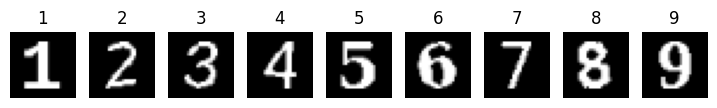

In [8]:

def make_digit_dataset(n_per_digit=600, seed=0):
    """Create CNN training data: digits 1-9 drawn in many fonts, sizes, positions and small
    rotations, then passed through the SAME cell_to_input() used for real cells, so training
    images and real Sudoku cells look alike."""
    rnd = random.Random(seed)
    X, y = [], []
    for digit in range(1, 10):
        for _ in range(n_per_digit):
            S = 64
            img = Image.new("L", (S, S), 255)
            d = ImageDraw.Draw(img)
            font = ImageFont.truetype(rnd.choice(FONT_FILES), rnd.randint(30, 46))   # random font + size
            d.text((S / 2 + rnd.uniform(-5, 5), S / 2 + rnd.uniform(-5, 5)),          # random small shift
                   str(digit), fill=0, font=font, anchor="mm")
            img = img.rotate(rnd.uniform(-8, 8), fillcolor=255)                       # random small rotation
            a = np.array(img)
            if rnd.random() < 0.5:
                a = cv2.GaussianBlur(a, (3, 3), 0)
            b = cv2.threshold(a, 128, 255, cv2.THRESH_BINARY_INV)[1]                  # digit -> white
            inp = cell_to_input(b)
            if inp is not None:
                X.append(inp); y.append(digit)
    return np.array(X), np.array(y)

X, y = make_digit_dataset(n_per_digit=600)
print(X.shape, y.shape)          # about 5,400 images of 28x28
fig, axes = plt.subplots(1, 9, figsize=(9, 1.3))
for d, a in zip(range(1, 10), axes):
    a.imshow(X[y == d][0], cmap="gray"); a.set_title(str(d)); a.axis("off")
plt.show()

### Step 7: Prepare the Data for PyTorch

In [9]:

import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split

# unsqueeze(1) adds the channel dimension: [N, 28, 28] -> [N, 1, 28, 28] (1 = greyscale)
data = TensorDataset(torch.tensor(X).unsqueeze(1), torch.tensor(y))
# 80% of the images for training, 20% kept aside to test accuracy on images the CNN never saw
train_set, test_set = random_split(data, [int(0.8 * len(data)), len(data) - int(0.8 * len(data))],
                                   generator=torch.Generator().manual_seed(0))
trainloader = DataLoader(train_set, batch_size=64, shuffle=True)
testloader  = DataLoader(test_set,  batch_size=256)
print(len(train_set), "train /", len(test_set), "test")

4284 train / 1072 test


### Step 8: CNN Model

In [10]:

class DigitNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3)        # 1 input channel (greyscale), 16 filters, 3x3 kernel
        self.pool  = nn.MaxPool2d(2, 2)         # halves the width and height
        self.conv2 = nn.Conv2d(16, 32, 3)       # 16 -> 32 filters, 3x3 kernel
        self.fc1   = nn.Linear(32 * 5 * 5, 64)  # flattened size: 32 channels x 5 x 5
        self.fc2   = nn.Linear(64, 10)          # 10 outputs = scores for digits 0-9

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))    # [N, 1, 28, 28] -> [N, 16, 13, 13]
        x = self.pool(F.relu(self.conv2(x)))    # [N, 16, 13, 13] -> [N, 32, 5, 5]
        x = torch.flatten(x, 1)                 # [N, 32, 5, 5] -> [N, 800]
        x = F.relu(self.fc1(x))                 # [N, 800] -> [N, 64]
        x = self.fc2(x)                         # [N, 64] -> [N, 10]
        return x

### Step 9: Train and Test the CNN

In [11]:
def test_accuracy(model):
    """Percentage of test images the CNN classifies correctly."""
    model.eval()                     # evaluation mode
    correct = total = 0
    with torch.no_grad():
        for images, labels in testloader:
            pred = model(images).argmax(1)     # class with the highest score = prediction
            correct += (pred == labels).sum().item(); total += labels.size(0)
    model.train()
    acc = 100 * correct / total
    print(f"Test accuracy: {acc:.2f} %")
    return acc

model = DigitNet()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)    # Adam optimiser, learning rate 0.001

for epoch in range(5):                                  # 5 passes over the training data
    running_loss = 0.0
    for inputs, labels in trainloader:
        optimizer.zero_grad()                           # reset gradients
        outputs = model(inputs)
        loss = criterion(outputs, labels)               # how wrong the predictions are
        loss.backward()                                 # calculate gradients
        optimizer.step()                                # update the weights
        running_loss += loss.item()
    print(f"Epoch {epoch + 1}: loss = {running_loss / len(trainloader):.4f}")
    test_accuracy(model)                                # accuracy on the 20% test images

print("Finished Training")


torch.save(model.state_dict(), "digitnet.pt")

Epoch 1: loss = 1.0229
Test accuracy: 99.63 %
Epoch 2: loss = 0.0196
Test accuracy: 99.91 %
Epoch 3: loss = 0.0041
Test accuracy: 99.91 %
Epoch 4: loss = 0.0015
Test accuracy: 99.91 %
Epoch 5: loss = 0.0007
Test accuracy: 99.91 %
Finished Training


### Step 10: Full Pipeline

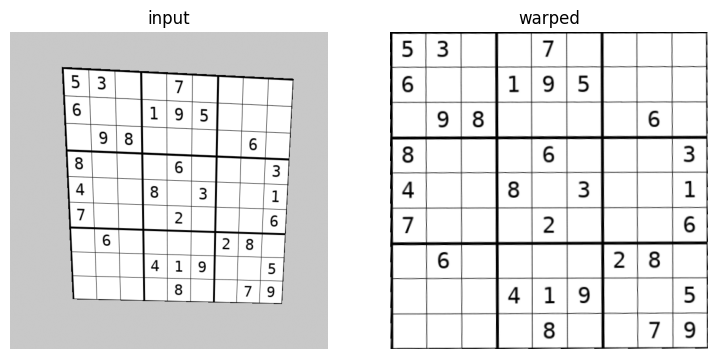

530070000600195000098000060800060003400803001700020006060000280000419005000080079
correct: True


In [12]:
def predict_digit(model, cell):
    """One 28x28 cell -> predicted digit (int)."""
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(cell).view(1, 1, 28, 28))
    return int(out.argmax(1))

def read_sudoku(image_path, model, show=False):
    """Image file -> 81-char puzzle string ('0' = empty). Returns None if no grid is found."""
    gray = cv2.imread(image_path, 0)                  # 0 = load as greyscale
    if gray is None:                                  # file missing or wrong name
        print("Could not open image:", image_path); return None
    corners = find_grid_corners(preprocess(gray))     # step 2 + 3
    if corners is None:
        print("No grid found in", image_path); return None
    warped = warp_grid(gray, corners)                 # step 4
    cells = split_cells(warped)                       # step 5: 81 cells (None = empty)
    # empty cell -> "0", otherwise ask the CNN which digit it is (step 7)
    puzzle = "".join("0" if c is None else str(predict_digit(model, c)) for c in cells)
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
        ax[0].imshow(gray, cmap="gray"); ax[0].set_title("input"); ax[0].axis("off")
        ax[1].imshow(warped, cmap="gray"); ax[1].set_title("warped"); ax[1].axis("off")
        plt.show()
    return puzzle

# Test
result = read_sudoku("test_tilted.png", model, show=True)
print(result)
print("correct:", result == TEST_PUZZLE)



## 3.3  Solving Methods

### 3.3.1–3.3.2 Method 1: CSP Search with MCV, LCV, Forward Checking and AC-3
 **Plain backtracking = baseline**, **MCV + LCV + AC-3 (MAC) = Method 1**, and MCV / MCV+LCV / FC

#### Board input/output and CSP utilities

In [13]:
from collections import deque
from copy import deepcopy
from pathlib import Path
from time import perf_counter

def string_to_board(puzzle_string):
    """Convert 81 Sudoku digits (0 = empty) into a 9x9 board."""
    digits = "".join(puzzle_string.split())
    if len(digits) != 81 or not digits.isdigit():
        raise ValueError("A Sudoku puzzle must contain exactly 81 digits (0–9).")
    return [[int(digits[row * 9 + col]) for col in range(9)] for row in range(9)]


def load_first_puzzle(file_path):
    """Load the first puzzle from a file with 9-digit rows and an optional header."""
    lines = [line.strip() for line in Path(file_path).read_text(encoding="utf-8").splitlines()
             if line.strip()]
    if not lines:
        raise ValueError("The Sudoku file is empty.")

    start = 0 if len(lines[0]) == 9 and lines[0].isdigit() else 1
    rows = lines[start:start + 9]
    if len(rows) != 9 or any(len(row) != 9 or not row.isdigit() for row in rows):
        raise ValueError("The file does not contain a valid first 9x9 Sudoku grid.")
    return [[int(char) for char in row] for row in rows]


def print_board(board):
    """Print a Sudoku board with separators between 3x3 boxes."""
    for row in range(9):
        if row > 0 and row % 3 == 0:
            print("------+-------+------")
        pieces = []
        for col in range(9):
            if col > 0 and col % 3 == 0:
                pieces.append("|")
            pieces.append(str(board[row][col]) if board[row][col] else ".")
        print(" ".join(pieces))

In [14]:
def find_empty(board):
    """Return the first empty cell as (row, col), or None if full."""
    for row in range(9):
        for col in range(9):
            if board[row][col] == 0:
                return row, col
    return None


def is_valid(board, row, col, num):
    """Return True if num can be assigned to (row, col)."""
    # Row constraint
    for c in range(9):
        if board[row][c] == num:
            return False

    # Column constraint
    for r in range(9):
        if board[r][col] == num:
            return False

    # 3x3 box constraint
    box_row = (row // 3) * 3
    box_col = (col // 3) * 3
    for r in range(box_row, box_row + 3):
        for c in range(box_col, box_col + 3):
            if board[r][c] == num:
                return False
    return True


def get_candidates(board, row, col):
    """List valid candidate values for an empty cell."""
    if board[row][col] != 0:
        return []
    return [num for num in range(1, 10) if is_valid(board, row, col, num)]

def get_neighbours(row, col):
    """Return all 20 distinct Sudoku peers of a cell."""
    neighbours = set()

    # Cells in the same row and column
    for i in range(9):
        neighbours.add((row, i))
        neighbours.add((i, col))

    # Cells in the same 3x3 box
    box_row = (row // 3) * 3
    box_col = (col // 3) * 3  # Fixed: use col, not row.
    for r in range(box_row, box_row + 3):
        for c in range(box_col, box_col + 3):
            neighbours.add((r, c))

    neighbours.remove((row, col))
    return neighbours


def check_solution(board, original):
    """Verify a completed Sudoku solution and preserve its given clues."""
    required = set(range(1, 10))
    if len(board) != 9 or len(original) != 9:
        return False
    if any(len(row) != 9 for row in board) or any(len(row) != 9 for row in original):
        return False

    # A valid answer must keep all original fixed cells unchanged.
    for row in range(9):
        for col in range(9):
            if original[row][col] != 0 and board[row][col] != original[row][col]:
                return False

    for row in board:
        if set(row) != required:
            return False

    for col in range(9):
        if {board[row][col] for row in range(9)} != required:
            return False

    for box_row in range(0, 9, 3):
        for box_col in range(0, 9, 3):
            values = {
                board[row][col]
                for row in range(box_row, box_row + 3)
                for col in range(box_col, box_col + 3)
            }
            if values != required:
                return False
    return True

#### Baseline: plain backtracking

In [15]:
def sol_backtracking(board, stats=None):
    """Plain backtracking; optionally track recursive calls and backtracks."""
    if stats is None:
        stats = {"nodes": 0, "backtracks": 0}
    stats["nodes"] += 1

    empty = find_empty(board)
    if empty is None:
        return True
    row, col = empty

    for num in range(1, 10):
        if is_valid(board, row, col, num):
            board[row][col] = num
            if sol_backtracking(board, stats):
                return True
            board[row][col] = 0
            stats["backtracks"] += 1
    return False


def sol_backtracking_counted(board, stats):
    """Backward-compatible name from the original notebook."""
    return sol_backtracking(board, stats)

#### Ablation: MCV and MCV + LCV

In [16]:
def find_mcv(board):
    """Return the unassigned cell with the fewest legal candidates."""
    best_cell = None
    min_candidates = 10

    for row in range(9):
        for col in range(9):
            if board[row][col] == 0:
                candidate_count = len(get_candidates(board, row, col))
                if candidate_count < min_candidates:
                    min_candidates = candidate_count
                    best_cell = (row, col)
    return best_cell


def sol_mcv(board, stats):
    """Backtracking with Most Constrained Variable selection."""
    stats["nodes"] += 1
    empty = find_mcv(board)
    if empty is None:
        return True
    row, col = empty

    for num in get_candidates(board, row, col):
        board[row][col] = num
        if sol_mcv(board, stats):
            return True
        board[row][col] = 0
        stats["backtracks"] += 1
    return False

def order_lcv(board, row, col):
    """Sort legal values by how few peer domains they would restrict."""
    candidates = get_candidates(board, row, col)
    neighbours = get_neighbours(row, col)

    def count_restrictions(num):
        count = 0
        for r, c in neighbours:
            if board[r][c] == 0 and num in get_candidates(board, r, c):
                count += 1
        return count

    return sorted(candidates, key=count_restrictions)


def sol_mcv_lcv(board, stats):
    """Backtracking with MCV variable selection and LCV value ordering."""
    stats["nodes"] += 1
    empty = find_mcv(board)
    if empty is None:
        return True
    row, col = empty

    for num in order_lcv(board, row, col):
        board[row][col] = num
        if sol_mcv_lcv(board, stats):
            return True
        board[row][col] = 0
        stats["backtracks"] += 1
    return False

#### Ablation: MCV + LCV + Forward Checking

In [17]:
# Shared representation for domain-based inference algorithms.
CELLS = tuple((r, c) for r in range(9) for c in range(9))
CSP_PEERS = {cell: tuple(sorted(get_neighbours(*cell))) for cell in CELLS}


def make_domains(board):
    """Build current candidate domains; return None for inconsistent clues."""
    if len(board) != 9 or any(len(row) != 9 for row in board):
        raise ValueError("Expected a 9x9 board.")

    domains = {}
    for row, col in CELLS:
        value = board[row][col]
        if not isinstance(value, int) or value not in range(10):
            raise ValueError("Sudoku cells must be integers in 0..9.")
        if value:
            # Original clues must not violate row/column/box constraints.
            if any(board[rr][cc] == value for rr, cc in CSP_PEERS[(row, col)]):
                return None
            domains[(row, col)] = {value}
        else:
            domains[(row, col)] = set(get_candidates(board, row, col))
        if not domains[(row, col)]:
            return None
    return domains


def copy_domains(domains):
    """Each recursive branch must have its own mutable domain sets."""
    return {cell: values.copy() for cell, values in domains.items()}


def find_mcv_domains(board, domains):
    """Select the unfilled cell with the smallest *propagated* domain."""
    unfilled = [cell for cell in CELLS if board[cell[0]][cell[1]] == 0]
    return min(unfilled, key=lambda cell: (len(domains[cell]), cell)) if unfilled else None


def order_lcv_domains(board, domains, cell):
    """Prefer values that eliminate the fewest options in unfilled peers."""
    open_peers = [peer for peer in CSP_PEERS[cell] if board[peer[0]][peer[1]] == 0]
    return sorted(
        domains[cell],
        key=lambda value: (sum(value in domains[peer] for peer in open_peers), value)
    )


def forward_check(domains, assigned_cell, stats=None):
    """Remove a newly assigned value from all peers; fail on empty domains."""
    if len(domains[assigned_cell]) != 1:
        raise ValueError("Forward Checking requires an assigned singleton domain.")
    value = next(iter(domains[assigned_cell]))
    for peer in CSP_PEERS[assigned_cell]:
        if value in domains[peer]:
            domains[peer].remove(value)
            if stats is not None:
                stats["domain_prunings"] += 1
            if not domains[peer]:
                return False
    return True


def search_with_domains(board, domains, stats, inference):
    """One depth-first search implementation for FC and AC-3 (MAC)."""
    stats["nodes"] += 1
    cell = find_mcv_domains(board, domains)
    if cell is None:
        return True
    row, col = cell
    if not domains[cell]:
        return False

    for value in order_lcv_domains(board, domains, cell):
        # Preserve domains across branches so backtracking is fully reversible.
        trial_domains = copy_domains(domains)
        trial_domains[cell] = {value}
        board[row][col] = value

        if inference == "fc":
            consistent = forward_check(trial_domains, cell, stats)
        elif inference == "ac3":
            # After X=val, reconsider every incoming peer -> X arc.
            consistent = ac3(
                trial_domains,
                arcs=[(peer, cell) for peer in CSP_PEERS[cell]],
                stats=stats,
            )
        else:
            raise ValueError(f"Unknown inference strategy: {inference}")

        if consistent and search_with_domains(board, trial_domains, stats, inference):
            return True

        board[row][col] = 0
        stats["backtracks"] += 1
    return False


def sol_mcv_lcv_fc(board, stats):
    """MCV + LCV with Forward Checking after every assignment."""
    stats.setdefault("domain_prunings", 0)
    stats.setdefault("arcs_checked", 0)
    domains = make_domains(board)
    if domains is None:
        return False
    return search_with_domains(board, domains, stats, inference="fc")


#### Method 1: MCV + LCV + AC-3 (MAC)

In [18]:
def revise(domains, xi, xj, stats=None):
    """Enforce Xi != Xj by removing Xi values without any support in Xj."""
    unsupported = {
        value_i for value_i in domains[xi]
        if not any(value_i != value_j for value_j in domains[xj])
    }
    if not unsupported:
        return False
    domains[xi].difference_update(unsupported)
    if stats is not None:
        stats["domain_prunings"] += len(unsupported)
    return True


def ac3(domains, arcs=None, stats=None):
    """Enforce arc consistency; return False if a domain is wiped out."""
    if any(not values for values in domains.values()):
        return False

    if arcs is None:
        # Each neighbor relation contributes two  arcs.
        arcs = [(xi, xj) for xi in CELLS for xj in CSP_PEERS[xi]]
    queue = deque(arcs)

    while queue:
        xi, xj = queue.popleft()
        if stats is not None:
            stats["arcs_checked"] += 1

        if revise(domains, xi, xj, stats):
            if not domains[xi]:
                return False
            # The changed domain of Xi may now restrict its other neighbors.
            for xk in CSP_PEERS[xi]:
                if xk != xj:
                    queue.append((xk, xi))
    return True


def sol_mcv_lcv_ac3(board, stats):
    """MCV + LCV with initial AC-3 and MAC inference per search choice."""
    stats.setdefault("domain_prunings", 0)
    stats.setdefault("arcs_checked", 0)
    domains = make_domains(board)
    if domains is None or not ac3(domains, stats=stats):
        return False
    return search_with_domains(board, domains, stats, inference="ac3")


#### Common format `solve_csp()` (+ baseline)


In [19]:
import signal

def _run_board_solver(solver, puzzle, time_limit):
    """Run one of Angel's board solvers on an 81-digit string, with a time limit."""
    board = string_to_board(puzzle)
    original = deepcopy(board)
    stats = {"nodes": 0, "backtracks": 0, "domain_prunings": 0, "arcs_checked": 0}

    def _timeout(signum, frame):
        raise TimeoutError
    signal.signal(signal.SIGALRM, _timeout)
    signal.alarm(int(time_limit))
    start = perf_counter()
    try:
        solved, timed_out = solver(board, stats), False
    except TimeoutError:
        solved, timed_out = False, True
    finally:
        signal.alarm(0)
    stats.update(time=perf_counter() - start, solved=bool(solved), timed_out=timed_out)

    if solved and check_solution(board, original):
        return "".join(str(v) for row in board for v in row), stats
    return None, stats

def solve_csp(puzzle, time_limit=15):
    """Method 1: MCV + LCV + AC-3 (MAC)."""
    return _run_board_solver(sol_mcv_lcv_ac3, puzzle, time_limit)

def solve_backtracking(puzzle, time_limit=15):
    """Baseline: plain backtracking."""
    return _run_board_solver(sol_backtracking, puzzle, time_limit)

#### Ablation table: what each CSP add-on contributes


In [20]:
SOLVERS = [
    ("Backtracking", sol_backtracking),
    ("MCV", sol_mcv),
    ("MCV + LCV", sol_mcv_lcv),
    ("MCV + LCV + FC", sol_mcv_lcv_fc),
    ("MCV + LCV + AC-3", sol_mcv_lcv_ac3),
]
ABLATION_PUZZLES = {
    "easy": "530070000600195000098000060800060003400803001700020006060000280000419005000080079",
    "hard": "800000000003600000070090200050007000000045700000100030001000068008500010090000400",
}
for name, p in ABLATION_PUZZLES.items():
    print(f"\n=== {name} ===")
    print(f'{"Method":<19} {"Solved":<7} {"Time (s)":>9} {"Nodes":>8} {"Backtracks":>10}')
    for mname, fn in SOLVERS:
        sol, st = _run_board_solver(fn, p, 15)
        print(f'{mname:<19} {str(sol is not None):<7} {st["time"]:>9.3f} {st["nodes"]:>8} {st["backtracks"]:>10}')


=== easy ===
Method              Solved   Time (s)    Nodes Backtracks
Backtracking        True        0.043     4209       4157
MCV                 True        0.013       52          0
MCV + LCV           True        0.017       52          0
MCV + LCV + FC      True        0.011       52          0
MCV + LCV + AC-3    True        0.010       52          0

=== hard ===
Method              Solved   Time (s)    Nodes Backtracks
Backtracking        True        0.509    49559      49498
MCV                 True        5.213    10102      10041
MCV + LCV           True        4.163     9265       9204
MCV + LCV + FC      True        0.584     8355       9204
MCV + LCV + AC-3    True        0.999     2800       3649


### 3.3.3 Method 2: Simulated Annealing

In [21]:
import random, math, time
import numpy as np

# start with every 3x3 box already valid
def sa_initial_state(grid, rnd):
    state = grid[:]
    for box in BOXES:
        missing = list(set(range(1, 10)) - {grid[i] for i in box if grid[i]})
        rnd.shuffle(missing)
        for i in box:
            if not grid[i]:
                state[i] = missing.pop()
    return state

# cost = missing digits in rows and columns (0 = solved)
def sa_cost(state):
    return sum(9 - len({state[i] for i in u}) for u in ROWS + COLS)

#  swap two non-clue cells in the same box
def sa_neighbour(state, free_by_box, rnd):
    box = rnd.choice([b for b in free_by_box if len(b) >= 2])
    a, b = rnd.sample(box, 2)
    new = state[:]
    new[a], new[b] = new[b], new[a]
    return new


def solve_sa(puzzle, time_limit=30, alpha=0.99, reheat_after=80, seed=None):
    rnd = random.Random(seed)
    grid = parse(puzzle)
    stats = {"nodes": 0, "reheats": 0}
    start = time.perf_counter(); solution = None

    if clues_consistent(puzzle):
        free_by_box = [[i for i in box if not grid[i]] for box in BOXES]
        n_free = sum(len(b) for b in free_by_box)
        if n_free == 0:
            solution = puzzle
        else:
            state = sa_initial_state(grid, rnd)
            cost = sa_cost(state)
            sample = [sa_cost(sa_neighbour(state, free_by_box, rnd)) for _ in range(200)]
            T0 = max(float(np.std(sample)), 0.5); T = T0           # starting temperature
            L = n_free ** 2                                        # swaps per temperature level
            best, no_improve = cost, 0

            while cost > 0 and time.perf_counter() - start < time_limit:
                for _ in range(L):
                    new = sa_neighbour(state, free_by_box, rnd)
                    new_cost = sa_cost(new); stats["nodes"] += 1
                    d = new_cost - cost
                    if d <= 0 or rnd.random() < math.exp(-d / T):  # acceptance rule
                        state, cost = new, new_cost
                        if cost == 0: break
                if cost < best: best, no_improve = cost, 0
                else: no_improve += 1
                if no_improve >= reheat_after:
                    T = T0; no_improve = 0; stats["reheats"] += 1
                else:
                    T *= alpha
            if cost == 0:
                solution = to_string(state)

    elapsed = time.perf_counter() - start
    stats.update(time=elapsed, solved=solution is not None,
                 timed_out=solution is None and elapsed >= time_limit)
    return solution, stats

### 3.3.4 Method 3: AC-3 + Gibbs Sampling

In [22]:
# constraint propagation
def propagate(grid):
    domains = [{v} if v else set(range(1, 10)) for v in grid]
    changed = True
    while changed:
        changed = False
        for i in range(81):
            if len(domains[i]) == 1:
                v = next(iter(domains[i]))
                for p in PEERS[i]:
                    if v in domains[p]:
                        domains[p] = domains[p] - {v}; changed = True
                        if not domains[p]: return None             # no solution
    return domains

#  peers of cell i matter
def conflicts(state, i, v):
    return sum(state[p] == v for p in PEERS[i])

def total_conflicts(state):
    return sum(conflicts(state, i, state[i]) for i in range(81)) // 2

# Gibbs sampling
def solve_gibbs(puzzle, time_limit=30, T=0.3, mode="gibbs", use_ac3=True, seed=None):
    rnd = random.Random(seed)
    grid = parse(puzzle)
    stats = {"nodes": 0, "sweeps": 0}
    start = time.perf_counter(); solution = None

    domains = None
    if clues_consistent(puzzle):
        domains = propagate(grid) if use_ac3 else [{v} if v else set(range(1, 10)) for v in grid]

    if domains is not None:
        free = [i for i in range(81) if len(domains[i]) > 1]
        state = [next(iter(d)) if len(d) == 1 else rnd.choice(sorted(d)) for d in domains]
        cost = total_conflicts(state)
        while cost > 0 and time.perf_counter() - start < time_limit:
            rnd.shuffle(free)
            for i in free:
                vals = sorted(domains[i])
                cs = [conflicts(state, i, v) for v in vals]
                if mode == "icm":                                   # ICM: fewest conflicts
                    m = min(cs)
                    state[i] = rnd.choice([v for v, c in zip(vals, cs) if c == m])
                else:                                               # Gibbs: weight e^(-c/T)
                    w = [math.exp(-c / T) for c in cs]
                    state[i] = rnd.choices(vals, weights=w)[0]
                stats["nodes"] += 1
            stats["sweeps"] += 1
            cost = total_conflicts(state)
        if cost == 0:
            solution = to_string(state)

    elapsed = time.perf_counter() - start
    stats.update(time=elapsed, solved=solution is not None,
                 timed_out=solution is None and elapsed >= time_limit)
    return solution, stats

### Test Puzzles


In [23]:
# Test puzzles
TEST_PUZZLES = {
    "easy":    "530070000600195000098000060800060003400803001700020006060000280000419005000080079",
    "medium":  "000000907000420180000705026100904000050000040000507009920108000034059000507000000",
    "hard":    "800000000003600000070090200050007000000045700000100030001000068008500010090000400",
    "17_clue": "000000010400000000020000000000050407008000300001090000300400200050100000000806000",
    "invalid": "553070000600195000098000060800060003400803001700020006060000280000419005000080079",
}



##  Solution Display

In [24]:
import matplotlib.pyplot as plt
import numpy as np

def display_solution(original, solved):
    original = np.array(original).reshape(9, 9)
    solved = np.array(solved).reshape(9, 9)

    fig, ax = plt.subplots(figsize=(6, 6))

    # Draw Sudoku grid
    for i in range(10):
        width = 3 if i % 3 == 0 else 1 #create the 3*3 column
        ax.plot([i, i], [0, 9], color="black", linewidth=width)
        ax.plot([0, 9], [i, i], color="black", linewidth=width)

    # Display numbers
    for row in range(9):
        for col in range(9):
            number = solved[row][col]

            if original[row][col] != 0:#using different for identify
                color = "black"#back color original
            else:
                color = "blue"#blue for solution given

            ax.text(col + 0.5, row + 0.5, str(number),#make sure the number are center
                    ha="center", va="center",
                    fontsize=18, color=color)

    ax.set_xlim(0, 9)
    ax.set_ylim(9, 0)
    ax.axis("off")
    ax.set_title("Sudoku Solution")

    plt.show()

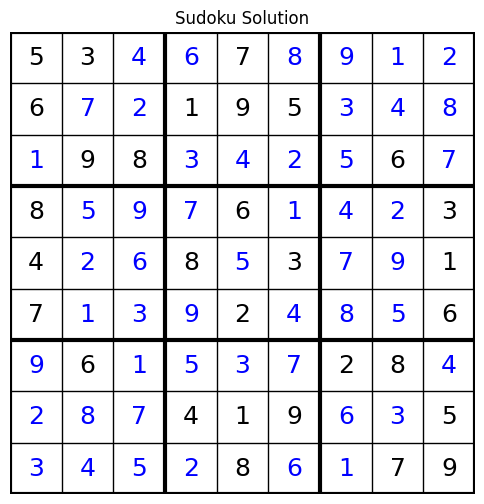

In [25]:
# Example: solve the easy puzzle with Method 2 and display it
p = TEST_PUZZLES["easy"]
sol, st = solve_sa(p, time_limit=20, seed=1)
if sol:
    display_solution(parse(p), parse(sol))
else:
    print("No solution found")

## 3.4 Evaluation Methodology and Results
Every method runs on the **same puzzles**; the random methods (2 and 3) run with **5 seeds** each. Output: **solve rate** and **average time** per puzzle and method. Replace `TEST_PUZZLES` with the final 20-puzzle set when ready.

3.4.1 Experimental setup  and metrics

In [26]:
import pandas as pd

METHODS = {
    "Baseline: plain backtracking":  (lambda p, s: solve_backtracking(p, time_limit=15), False),
    "Method 1: CSP (MCV+LCV+AC-3)":  (lambda p, s: solve_csp(p, time_limit=15), False),
    "Method 2: Simulated annealing": (lambda p, s: solve_sa(p, time_limit=15, seed=s), True),
    "Method 3: Gibbs + AC-3":        (lambda p, s: solve_gibbs(p, time_limit=15, seed=s), True),
    "ICM + AC-3 (comparison)":       (lambda p, s: solve_gibbs(p, time_limit=15, seed=s, mode="icm"), True),
}
SEEDS = range(5)

SUDOKU_PUZZLES = {
    "easy": [
        "530070000600195000098000060800060003400803001700020006060000280000419005000080079",
        "003020600900305001001806400008102900700000008006708200002609500800203009005010300",
        "000260701680070090190004500820100040004602900050003028009300074040050036703018000",
        "004300209005009001070060043006002087190007400050083000600000105003508690042910300",
    ],
    "medium": [
        "200080300060070084030500209000105408000000000402706000301007040720040060004010003",
        "000000907000420180000705026100904000050000040000507009920108000034059000507000000",
        "000900002050123400030000160908000000070000090000000205091000050007439020400007000",
        "000020657900300001050000000500100000000064000030008045070080500014203060000400000",
    ],
    "hard": [
        "100007090030020008009600500005300900010080002600004000300000010040000007007000300",
        "800000000003600000070090200050007000000045700000100030001000068008500010090000400",
        "100000002090400050006000700050903000000070000000850040700000600030009080002000001",
        "000000000000003085001020000000507000004000100090000000500000073002010000000040009",
    ],
    "17_clue": [
        "400000805030000000000700000020000060000080400000010000000603070500200000104000000",
        "520006000000000701300000000000400800600000050000000000041800000000030020008700000",
        "600000803040700000000000000000504070300200000106000000020000050000080600000010000",
        "000000010400000000020000000000050407008000300001090000300400200050100000000806000",
    ],
}

INVALID_PUZZLES = [
    "553070000600195000098000060800060003400803001700020006060000280000419005000080079",
    "530070000500195000098000060800060003400803001700020006060000280000419005000080079",
    "530070000650195000098000060800060003400803001700020006060000280000419005000080079",
    "530070000660195000098000060800060003400803001700020006060000280000419005000080079",
]
print("Invalid puzzles rejected by input check:",
      sum(not clues_consistent(p) for p in INVALID_PUZZLES), "/", len(INVALID_PUZZLES))

Invalid puzzles rejected by input check: 4 / 4


In [27]:
rows = []
for group, puzzle_list in SUDOKU_PUZZLES.items():
    for mname, (fn, uses_seed) in METHODS.items():
        for p_idx, p in enumerate(puzzle_list):
            for seed in (SEEDS if uses_seed else [0]):
                sol, st = fn(p, seed)
                rows.append({"group": group,
                             "puzzle_id": f"{group}_{p_idx + 1}",
                             "method": mname,
                             "seed": seed,
                             "solved": is_valid_solution(p, sol),
                             "time": min(st["time"], 15.0),
                             "nodes": st.get("nodes", 0),
                             "backtracks": st.get("backtracks", 0),
                             "reheats": st.get("reheats", 0),
                             "domain_prunings": st.get("domain_prunings", 0)})
        print("done:", group, "-", mname)

results = pd.DataFrame(rows)
results.to_csv("solver_results.csv", index=False)

done: easy - Baseline: plain backtracking
done: easy - Method 1: CSP (MCV+LCV+AC-3)
done: easy - Method 2: Simulated annealing
done: easy - Method 3: Gibbs + AC-3
done: easy - ICM + AC-3 (comparison)
done: medium - Baseline: plain backtracking
done: medium - Method 1: CSP (MCV+LCV+AC-3)
done: medium - Method 2: Simulated annealing
done: medium - Method 3: Gibbs + AC-3
done: medium - ICM + AC-3 (comparison)
done: hard - Baseline: plain backtracking
done: hard - Method 1: CSP (MCV+LCV+AC-3)
done: hard - Method 2: Simulated annealing
done: hard - Method 3: Gibbs + AC-3
done: hard - ICM + AC-3 (comparison)
done: 17_clue - Baseline: plain backtracking
done: 17_clue - Method 1: CSP (MCV+LCV+AC-3)
done: 17_clue - Method 2: Simulated annealing
done: 17_clue - Method 3: Gibbs + AC-3
done: 17_clue - ICM + AC-3 (comparison)


In [29]:
summary = results.groupby(["group", "method"]).agg(
    solve_rate=("solved", lambda x: f"{100 * x.mean():.0f} %"),
    avg_time_s=("time", lambda x: round(x.mean(), 2)),
    avg_nodes=("nodes", lambda x: int(x.mean())),
    avg_backtracks=("backtracks", lambda x: int(x.mean()))
).unstack(level="group")

metrics = ["solve_rate", "avg_time_s", "avg_nodes", "avg_backtracks"]
groups = ["easy", "medium", "hard", "17_clue"]
summary = summary.reindex(columns=metrics, level=0).reindex(columns=groups, level=1)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1500)

for m in metrics:
    print(f"\n--- Metric: {m} ---")
    metric_table = summary[m]
    display(metric_table) if 'display' in globals() else print(metric_table)


--- Metric: solve_rate ---
group                           easy medium   hard 17_clue
method                                                    
Baseline: plain backtracking   100 %  100 %   75 %    25 %
ICM + AC-3 (comparison)        100 %    0 %    0 %     0 %
Method 1: CSP (MCV+LCV+AC-3)   100 %  100 %  100 %   100 %
Method 2: Simulated annealing  100 %   60 %    0 %     0 %
Method 3: Gibbs + AC-3         100 %  100 %   20 %     5 %

--- Metric: avg_time_s ---
group                          easy  medium   hard  17_clue
method                                                     
Baseline: plain backtracking   0.02    0.58   4.92    11.46
ICM + AC-3 (comparison)        0.00   15.00  15.00    15.00
Method 1: CSP (MCV+LCV+AC-3)   0.02    0.02   2.44     0.37
Method 2: Simulated annealing  3.12    9.70  15.00    15.00
Method 3: Gibbs + AC-3         0.00    0.77  13.73    14.58

--- Metric: avg_nodes ---
group                            easy   medium     hard  17_clue
method             

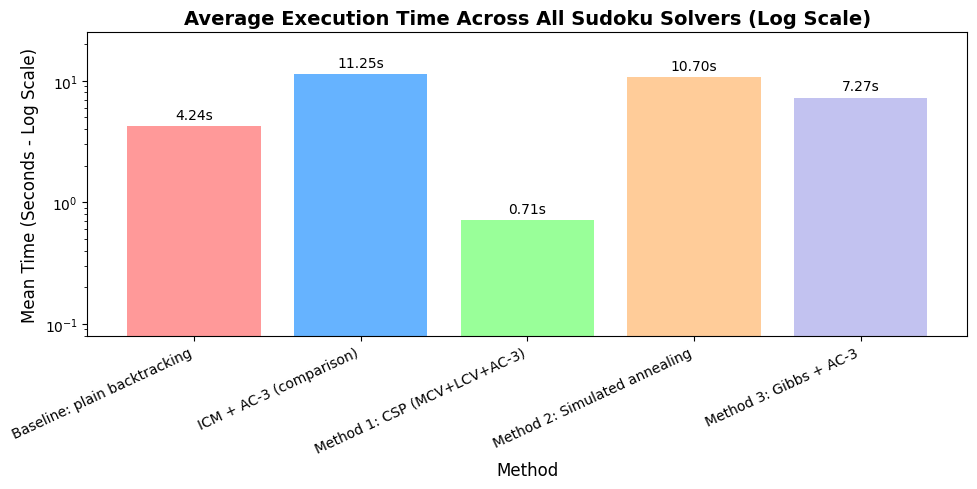

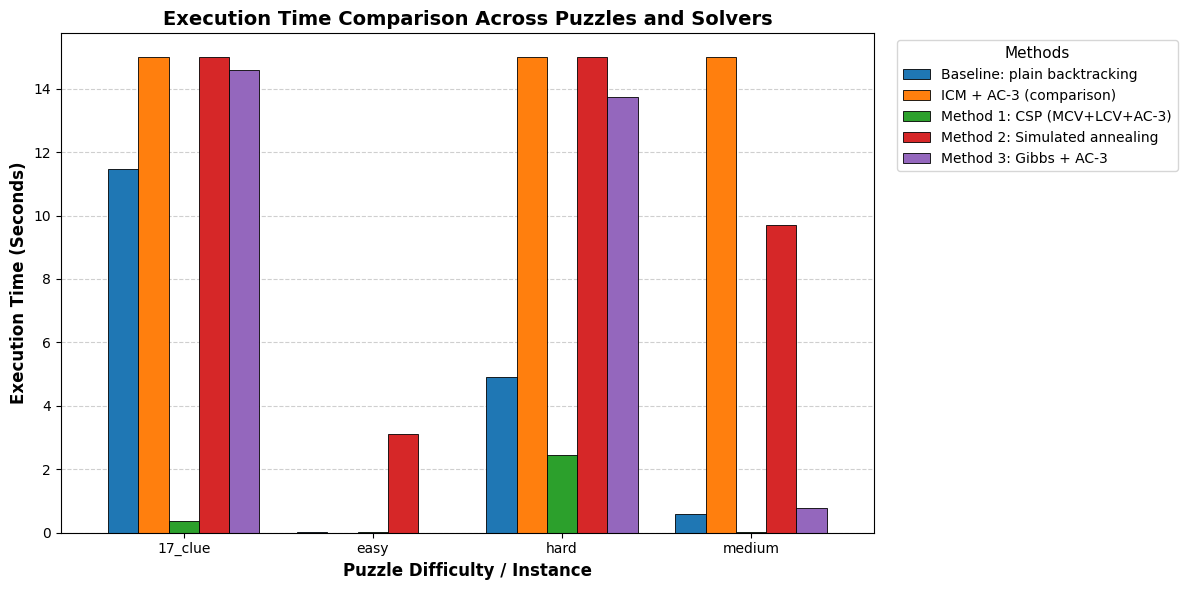

In [30]:
if 'results' in locals():
    avg_time_by_method = results.groupby("method")["time"].mean()

    fig, ax = plt.subplots(figsize=(10, 5))


    bars = ax.bar(avg_time_by_method.index, avg_time_by_method.values,
                  color=['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0'])

    ax.set_yscale('log')

    ax.set_ylim(bottom=0.08, top=25)

    ax.set_title("Average Execution Time Across All Sudoku Solvers (Log Scale)", fontsize=14, fontweight='bold')
    ax.set_xlabel("Method", fontsize=12)
    ax.set_ylabel("Mean Time (Seconds - Log Scale)", fontsize=12)
    plt.xticks(rotation=25, ha='right')


    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}s',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.show()

print("\n\n")

if 'results' in locals():

    pivot_time = results.pivot_table(index="group", columns="method", values="time", aggfunc="mean")


    fig, ax = plt.subplots(figsize=(12, 6))
    pivot_time.plot(kind='bar', ax=ax, edgecolor='black', linewidth=0.6, width=0.8)

    ax.set_title("Execution Time Comparison Across Puzzles and Solvers", fontsize=14, fontweight='bold')
    ax.set_xlabel("Puzzle Difficulty / Instance", fontsize=12, fontweight='bold')
    ax.set_ylabel("Execution Time (Seconds)", fontsize=12, fontweight='bold')


    plt.xticks(rotation=0, fontsize=10)
    plt.yticks(fontsize=10)


    ax.yaxis.grid(True, linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)


    ax.legend(title="Methods", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10, title_fontsize=11)

    plt.tight_layout()
    plt.show()

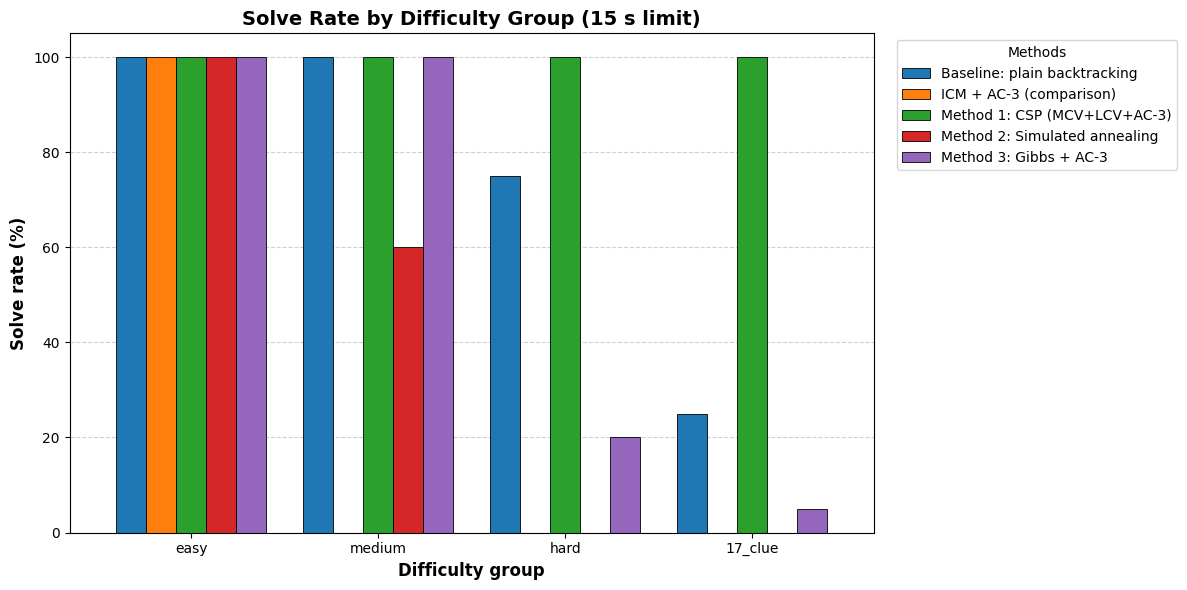

In [31]:
# Chart 3: solve rate by difficulty group (the main result)
if 'results' in locals():
    order = ["easy", "medium", "hard", "17_clue"]
    pivot_rate = (results.pivot_table(index="group", columns="method", values="solved", aggfunc="mean")
                  .reindex(order) * 100)

    fig, ax = plt.subplots(figsize=(12, 6))
    pivot_rate.plot(kind="bar", ax=ax, edgecolor="black", linewidth=0.6, width=0.8)
    ax.set_title("Solve Rate by Difficulty Group (15 s limit)", fontsize=14, fontweight="bold")
    ax.set_xlabel("Difficulty group", fontsize=12, fontweight="bold")
    ax.set_ylabel("Solve rate (%)", fontsize=12, fontweight="bold")
    ax.set_ylim(0, 105)
    plt.xticks(rotation=0)
    ax.yaxis.grid(True, linestyle="--", alpha=0.6); ax.set_axisbelow(True)
    ax.legend(title="Methods", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
